# Исследовательский анализ данных

**Цель работы:**

Изучение связи между признаками двумерного набора данных, визуализация данных.

### Описание предметной области

Вариант №1

Набор данных: датасет drivers.csv содержит информацию о поездках такси.  
Атрибуты:
1. Дата и время начала
2. Дата и время окончания
3. Категория
4. Место начала (можно не проверять данный столбец на наличие
неявных дубликатов)
5. Место окончания (можно не проверять данный столбец на наличие
неявных дубликатов)
6. Пройденные мили
7. Цель поездки
8. Время поездки в минутах
9. Скорость в пути
10. Цена поездки

### 1. Чтение файла и обзор данных

#### 1.1 Знакомство со структурой таблицы с помощью метода head

Загрузка датасета с помощью библиотеки pandas. Исходные табличные данные преобразуются в датафрейм. 

In [1]:
import pandas as pd

df = pd.read_csv('drivers2.csv')
df.head()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,time,speed,price
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000,788.0
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,NaN,12.0,25.000000,1237.0
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846,1312.0
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857,1387.0
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776,5376.0


Для целостности названия всех полей приводятся к единому виду: латинские строчные буквы, без лишних символов.

In [2]:
df = df.rename(columns={'START_DATE*':'start_date', 'END_DATE*':'end_date', 'CATEGORY*':'category', 'START*':'start_loc', 'STOP*':'stop_loc', 'MILES*':'miles', 'PURPOSE*':'purpose'})

#### 1.2 Оценка данных

Данные, которые хранятся в csv-файлах и используются для анализа, могут содержать ошибки, которые необходимо устранить перед непосредственным анализом. Метод info() предоставляет общую информацию о таблице: её размеры, названия столбцов, типы данных значений, хранящихся в них, а также количество ненулевых значений в каждом столбце.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1099 entries, 0 to 1098
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   start_date  1099 non-null   str    
 1   end_date    1099 non-null   str    
 2   category    1099 non-null   str    
 3   start_loc   1099 non-null   str    
 4   stop_loc    1099 non-null   str    
 5   miles       1099 non-null   float64
 6   purpose     598 non-null    str    
 7   time        1099 non-null   float64
 8   speed       1099 non-null   float64
 9   price       1099 non-null   float64
dtypes: float64(4), str(6)
memory usage: 162.9 KB


In [4]:
df.describe()

C:\AppDataScience\anaconda3\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,miles,time,speed,price
count,1099.000000,1099.000000,1099.000000,1099.000000
mean,10.803094,23.300273,inf,2085.929936
std,22.044580,27.745836,NaN,2084.368402
min,0.500000,0.000000,3.917355,337.000000
25%,2.900000,10.000000,15.346667,1087.000000
50%,6.000000,16.000000,21.333333,1539.000000
75%,10.500000,27.000000,28.915033,2365.500000
max,310.300000,336.000000,inf,25569.000000


Значения стандартного отклонения и среднего считаются некорректно, поскольку есть строки с нулевой продолжительностью поездки. Такие данные являются мусорными, от них нужно избавиться.

#### 1.3 Предобработка данных

Процесс предобработки данных подробно описан в предыдущей лабораторной работе. 
В него входят следующие этапы:
- заполнение/удаление пропусков
- работа с явными/неявными дубликатами
- приведение значений к корректному типу данных

In [5]:
import numpy as np
df.loc[df['time']==0, 'time'] = np.nan

In [6]:
df.isna().sum()

start_date      0
end_date        0
category        0
start_loc       0
stop_loc        0
miles           0
purpose       501
time            4
speed           0
price           0
dtype: int64

Поле PURPOSE содержит 501 пропуск, ячейки будут заполнены "Unknown purpose". В поле time пропущено всего 4 значения, эти строки можно удалить.

In [7]:
df['purpose'] = df['purpose'].fillna('Unknown Purpose')
df = df.dropna(subset='time').reset_index(drop=True)
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   start_date  1095 non-null   str    
 1   end_date    1095 non-null   str    
 2   category    1095 non-null   str    
 3   start_loc   1095 non-null   str    
 4   stop_loc    1095 non-null   str    
 5   miles       1095 non-null   float64
 6   purpose     1095 non-null   str    
 7   time        1095 non-null   float64
 8   speed       1095 non-null   float64
 9   price       1095 non-null   float64
dtypes: float64(4), str(6)
memory usage: 170.3 KB


start_date    0
end_date      0
category      0
start_loc     0
stop_loc      0
miles         0
purpose       0
time          0
speed         0
price         0
dtype: int64

Набор данных не содержит пропусков.

#### 1.4 Проверка типов данных

Поля start_date и end_date нужно привести к типу Datetime. Для этого используется функция to_datetime модуля pandas:

In [8]:
df['start_date'] = pd.to_datetime(df['start_date'], format = '%Y-%m-%d %H:%M:%S', errors='coerce')
df['end_date'] = pd.to_datetime(df['end_date'], format = '%Y-%m-%d %H:%M:%S', errors='coerce')
print(df['start_date'].dtype)
print(df['end_date'].dtype)

datetime64[us]
datetime64[us]


#### 1.5 Поиск дубликатов

Как было сказано ранее, дубликаты могут быть явными и неявными. Для поиска **явных** дубликатов достаточно использовать метод duplicated():

In [9]:
print(df.duplicated().sum())

0


Полностью одинаковых кортежей датафрейм не содержит. Для проверки **неявных** дубликатов используется метод поиска уникальных значений поля:

In [10]:
print(df['category'].unique())
print(df['purpose'].unique())

<ArrowStringArray>
['Business', 'Personal']
Length: 2, dtype: str
<ArrowStringArray>
[ 'Meal/Entertain', 'Unknown Purpose', 'Errand/Supplies',         'Meeting',
  'Customer Visit',  'Temporary Site', 'Between Offices',     'Charity ($)',
         'Commute',          'Moving',  'Airport/Travel']
Length: 11, dtype: str


Неявных дубликатов не обнаружено. 

### 2. Исследовательский анализ данных

**Визуализация данных** – один из самых мощных инструментов в EDA, который позволяет наглядно представить распределение данных, выявить тренды и зависимости.

#### 2.1 Построение точечной диаграммы

Для того чтобы обнаружить взаимосвязи между данными (например,
определить связь роста и веса, связь стоимости жилья от площади и т.д.)
могут применяться **диаграммы рассеивания** – особый тип графика, который
также называется scatter . На таком графике можно увидеть связь между
двумя величинами или её отсутствие, а также аномальные точки.

<Axes: xlabel='time', ylabel='price'>

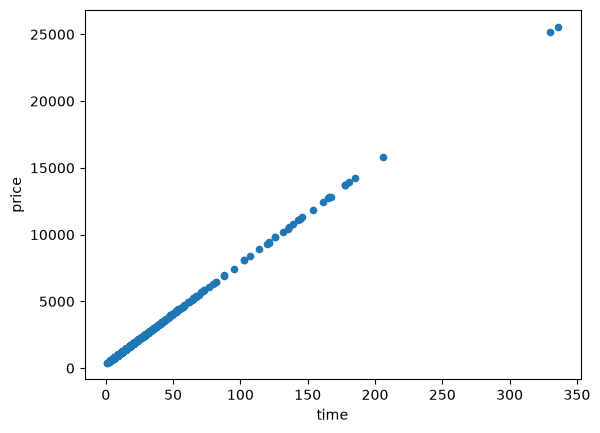

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

df.plot(x='time', y='price', kind='scatter')    # проверка зависимости цены от времени - pandas
# plt.scatter(df['time'], df['price']) # matplotlib
# sns.scatterplot(data = df, x='time', y='price') # seaborn

Также можно использовать **матрицу диаграмм рассеяния** для нескольких
признаков набора данных, которая отражает попарные взаимосвязи величин. Дл анализа данного датасета это удобный инструмент, т.к. имеются целых 4 числовых поля.

Использование инструмента **pairplot** библиотеки seaborn имеет большое количество настраиваемых параметров и позволяет разные категории отобразить на диаграмме разными цветами: 

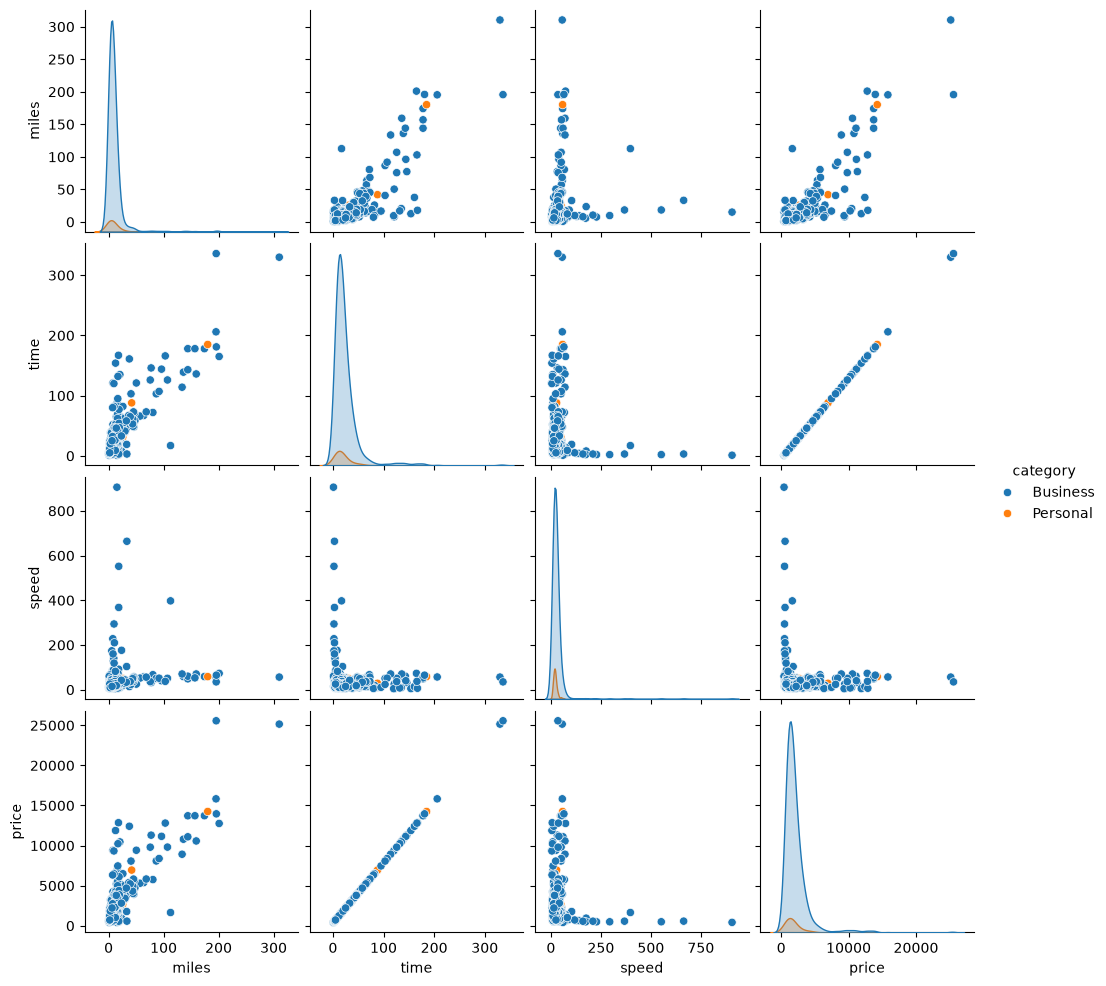

In [12]:
sns.pairplot(df[['miles','time','speed','price', 'category']], hue = 'category')
# pd.plotting.scatter_matrix(df, figsize=(9, 9))

Полученная матрица комплексно показывает зависимость между переменными.
- По диагонили матрицы расположены Подавляющее большинство поездок в датасете — короткие и дешевые (сосредоточены у левого края). Но есть небольшое количество очень долгих и дорогих поездок, которые образуют длинный хвост вправо. 
- Диаграмма time-price имеет линейный характер, что указывает на линейную зависимость между величинами. С учеличением времени поездки цена увеличивается в то же число раз. Видно, что есть несколько выбросов: в большинстве все точки лежат в области с time < 250, price < 16000, но есть пара точек, лежащие близко к границам диаграммы: для них time > 300, price > 23000. Однако и эти значения лежат на продолжении прямой, что говорит о согласованности с выводом о линейной связи. Скорее всего, поле price вычисляется из поля time умножением на какой-то коэффициент.
- miles-time закономерность сохраняется: чем больше миль, тем больше времени. Однако точки образуют не прямую линию, а широкое облако. За ожно и то же время можно проехать разное расстояние и наоборот: одно и то же рассояние может быть преодолено за разное время.

 Аномалии: на графиках с осью speed видно, что большинство точек сгруппировались в начале оси (<90 миль/час). Но также есть точки со скоростью > 250 и даже > 700, что для такси это физически невозможно - эти записи явно являются аномалиями. Поскольку speed это расчётный столбец, скорее всего ошибки были допущены при внесении дальности (miles) или продолжительности поездки (end_date, start_date). 
 Параметр hue метода pairplot позволил визуально радзелить данные по категории поездки. Поскольку на каждой диаграмме синие и оранжевые точки перемешаны, можно сделать вывод, что *категория поездки практически не влияет на базовые физические характеристики (время, мили, цена)*. Единственное, на что стоит обратить внимание - оранжевых точек (Personal) визуально в разы меньше, чем синих (Business).

#### 2.2 Построение гистограмм

**Гистограмма** - визуальное представление, которое демонстрирует
частоту встречаемости различных значений в наборе данных. В
данном графике числовые значения объединяются в интервалы, и
гистограмма показывает частоту значений в каждом из этих
интервалов.  
Воспользуемся методом *hist()* из библиотеки pandas для построения гистограмм числовых полей. Параметр *bins* определяет количество областей, на которые
следует разделить диапазон данных, по умолчанию это количество равно 10. Для более гибкой настройки графика можно пользоваться методом **subplots** из модуля matplotlib.pyplot:

Text(0.5, 0.98, 'Гистограммы числовых характеристик')

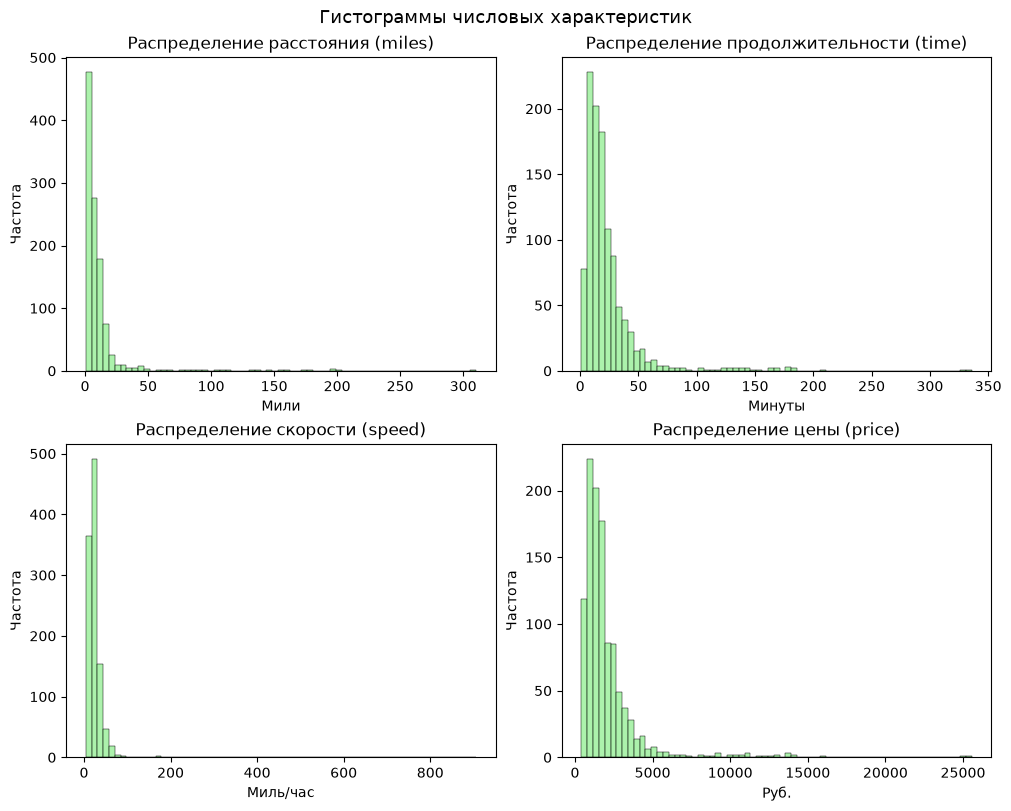

In [13]:
fig, axes = plt.subplots(
2, # две строки
2, # четыре графика
figsize=(10, 8), # размер графика
constrained_layout=True)

sns.histplot(df['miles'], ax = axes[0, 0], color='lightgreen', edgecolor='black')
axes[0, 0].set_title('Распределение расстояния (miles)')
axes[0, 0].set_xlabel('Мили')
axes[0, 0].set_ylabel('Частота')

sns.histplot(df['time'], ax = axes[0, 1], color='lightgreen', edgecolor='black')
axes[0, 1].set_title('Распределение продолжительности (time)')
axes[0, 1].set_xlabel('Минуты')
axes[0, 1].set_ylabel('Частота')

sns.histplot(df['speed'], ax = axes[1, 0], color='lightgreen', edgecolor='black')
axes[1, 0].set_title('Распределение скорости (speed)')
axes[1, 0].set_xlabel('Миль/час')
axes[1, 0].set_ylabel('Частота')

sns.histplot(df['price'], ax = axes[1, 1], color='lightgreen', edgecolor='black')
axes[1, 1].set_title('Распределение цены (price)')
axes[1, 1].set_xlabel('Руб.')
axes[1, 1].set_ylabel('Частота')

plt.suptitle('Гистограммы числовых характеристик', fontsize=13)

Библиотека Seaborn использует математические алгоритмы (например, правило Стёрджесса) для автоматического расчета **оптимального количества** корзин (bins). При использовании метода hist() модуля pandas, нужно вручную подбирать количество областей bins. Если оставить значение по умолчанию bins=10, получится **неинформативная** гистограмма, практически все значения в которой находятся в первой области.  
По данным диаграммам можно сделать промежуточный вывод: ни один из числовых признаков (miles, time, speed, price) не имеет нормального распределения. Все они имеют ярко выраженную правостороннюю асимметрию (длинный хвост справа) - уже замеченные ранее выбросы.

#### 2.3 Исследование взаимосвязи между переменными
##### 2.3.1 Корреляция
Исследовать взаимосвязь между переменными с помощью оценки коэффициента корреляции и ковариации. Построить heatmap (тепловую
карту корреляции). Выполнить интерпретацию результатов корреляции и ковариации, отвечая на вопросы о наличии (отсутствии) линейной
взаимосвязи между переменными. Понимать, что такое корреляция и ковариация. 

**Корреляция** – это статистическая мера зависимости между двумя переменными. Она позволяет определить, насколько две переменные изменяются вместе. Положительная корреляция означает, что увеличение одной переменной
связано с увеличением другой переменной. **Наличие корреляции не доказывает причинно-следственную связь, а указывает на статистическую зависимость.**  
Корреляция может быть измерена с помощью коэффициента корреляции, такого как **коэффициент Пирсона**. Он может принимать значения от -1 до 1:
- «1» – положительная корреляция;
- «–1» – отрицательная корреляция;
- 0 – отсутствие корреляции.
 
Корреляция Пирсона измеряет степень и направление **линейной взаимосвязи** между двумя переменными. Коэффициент Пирсона (обозначается как r) показывает, насколько близко точки данных на диаграмме рассеяния ложатся на прямую линию.  
Метод corr() по умолчанию считает именно коэффициент Пирсона:

In [14]:
df.corr(numeric_only=True)

,miles,time,speed,price
miles,1.000000,0.849977,0.192600,0.850889
time,0.849977,1.000000,0.005034,0.999998
speed,0.192600,0.005034,1.000000,0.005651
price,0.850889,0.999998,0.005651,1.000000


В отличие от метода Пирсона, который работает с непрерывными числовыми данными, **метод Спирмена** подходит для порядковых (ранговых) данных, а также для интервальных и данных отношений. К тому же он менее чувствителен к выбросам и не требует нормальности распределения данных.  
Поскольку в представленном датасете есть выбросы, проверим, как на результат повлияет переход на коэффициент Спирмена. В методе *corr()* указывается параметр *method='spearman'*: 

In [15]:
corr_matrix = df.corr(numeric_only=True, method='spearman')
display(corr_matrix)

,miles,time,speed,price
miles,1.000000,0.815769,0.629659,0.826049
time,0.815769,1.000000,0.136651,0.999699
speed,0.629659,0.136651,1.000000,0.154145
price,0.826049,0.999699,0.154145,1.000000


Использование метода Спирмена значительно изменило оценки корреляции для признака speed (например, связь с miles выросла с 0.19 до 0.63). Именно поле speed содержит экстремальные выбросы (аномально высокие скорости из-за ошибок в данных). Коэффициент Пирсона крайне чувствителен к таким выбросам, а Спирмен за счёт работы с рангами нивелирует их влияние, позволяя выявить **истинную монотонную зависимость**.  
Из полученной матрицы корреляций можно выявить "очень сильные" и "сильные" связи: 
- r(time-miles) = 0,82 > 0,8;
- r(price-miles) = 0,83 > 0,8;
- r(time-price) = 0,99 > 0,8 (идеальная линейная связь);
- r(speed-miles) = 0,63 > 0,6 (*нелинейная* монотонная связь).  

Остальные значения r говорят о слабой или очень слабой связи.

Тепловая карта корреляций строится методом heatmap модуля seaborn:

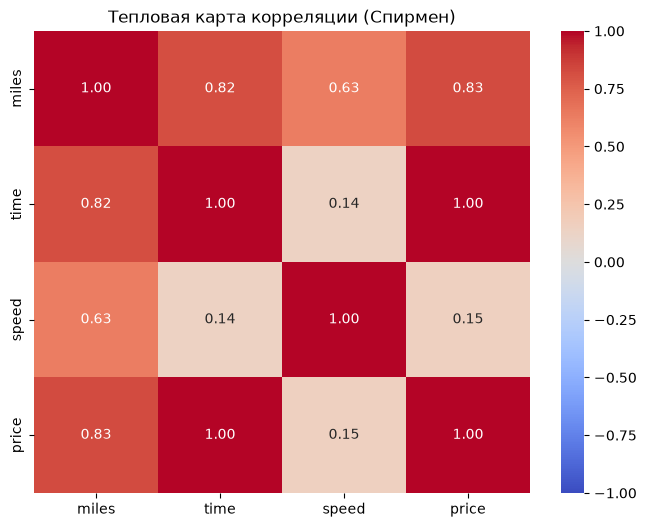

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, 
            annot=True,      # Показывать цифры внутри ячеек
            cmap='coolwarm', # Выбор цветовой схемы
            fmt='.2f',       # Округление до 2 знаков
            vmin=-1, vmax=1) # Фиксируем границы от -1 до 1
plt.title('Тепловая карта корреляции (Спирмен)')
plt.show()

Интерпретация: чем темнее клетка на пересечении двух числовых показателей, тем ближе к 1 их коэффициент корреляции.  
На основании проведённого анализа сделаем промежуточный вывод:
- Идеальная линейная связь time и price (r ≈ 1.0).
  Цена цена поездки в данном датасете рассчитывается как функция от времени в пути (вероятно, умножением на фиксированный коэффициент). Другие факторы (расстояние, скорость) на формирование цены не влияют.
- Сильная положительная связь miles с time и price (r ≈ 0.82–0.83).
  Чем больше расстояние, тем больше времени занимает поездка и тем выше её стоимость. Это соответствует бизнес-логике такси.
- Умеренная связь Спирмена между speed и miles (0.63).
  Можно интерпретировать так: длинные поездки чаще проходят по трассам, где средняя скорость выше, чем в коротких городских поездках.

##### 2.3.2 Ковариация
**Ковариация** — это мера совместной изменчивости двух случайных величин. Ключевая особенность ковариации — её **зависимость от единиц измерения** и масштаба переменных. Изученная ранее корреляция — это стандартизированная версия ковариации, которая устраняет влияние масштаба и единиц измерения за счёт деления на произведение стандартных отклонений обеих переменных.

In [17]:
df[['miles', 'time', 'speed', 'price']].cov()

,miles,time,speed,price
miles,484.414811,519.332857,187.193450,3.905647e+04
time,519.332857,770.653900,6.170935,5.789488e+04
speed,187.193450,6.170935,1950.082519,5.204055e+02
price,39056.466480,57894.879112,520.405543,4.349329e+06


Ковариация между величинами положительна (при увеличении одного показателя другой в среднем также увеличивается), однако абсолютное значение ковариации не позволяет судить о силе связи из-за разницы в масштабах признаков (например, минуты и рубли). Так например: 
- Ковариация time и price = 57 894;
- Ковариация time и speed = 6.17.  

Кажется, что связь времени и скорости в 10 000 раз слабее, чем связь времени и цены. На самом деле цена дело только в том, что цена измеряется в рублях (тысячи), а скорость в миль/ч (десятки). Поэтому предпочтительнее использовать нормированный коэффициент корреляции, который нивелирует влияние масштаба.

##### 2.3.3 Сравнение подходов
Ковариация оценивает только линейную совместную изменчивость. То есть если зависимость параболическая, ковариация может быть равна нулю, хотя связь очевидна. Однако ковариация не даёт судить о силе линейной связи.  
Коэффициент Пирсона — это нормированная ковариация. Он делит её на произведение стандартных отклонений, поэтому всегда находится в диапазоне от -1 до 1. По его значению можно судить о силе линейной связи: 0.9 — сильная линейная связь, 0.1 — слабая. Чувствителен к выбросам.  
Коэффициент Спирмена показывает направление и силу монотонной связи (-1 до 1). Устойчив к выбросам, работает с рангами. Если Спирмен = 1, связь идеально монотонна (может быть как линейной, так и нет).

#### 2.4 Задания индивидуального варианта
Вариант 1
##### Задание 1
Использовать seaborn. По группировке - CATEGORY и количество поездок каждого типа (по цели маршрута - PURPOSE) отфильтровать данные группировки по количеству поездок больше 2 и построить диаграмму.  
Важно различать изученную ранее гистограмму (предназначена для непрерывных числовых данных, группирует их в корзины (bins)) и столбчатую диаграмму (Bar Chart).

,purpose,category,count
1,Between Offices,Business,17
4,Customer Visit,Business,94
5,Errand/Supplies,Business,110
6,Meal/Entertain,Business,145
7,Meeting,Business,178
8,Moving,Personal,4
9,Temporary Site,Business,46
10,Unknown Purpose,Business,426
11,Unknown Purpose,Personal,71


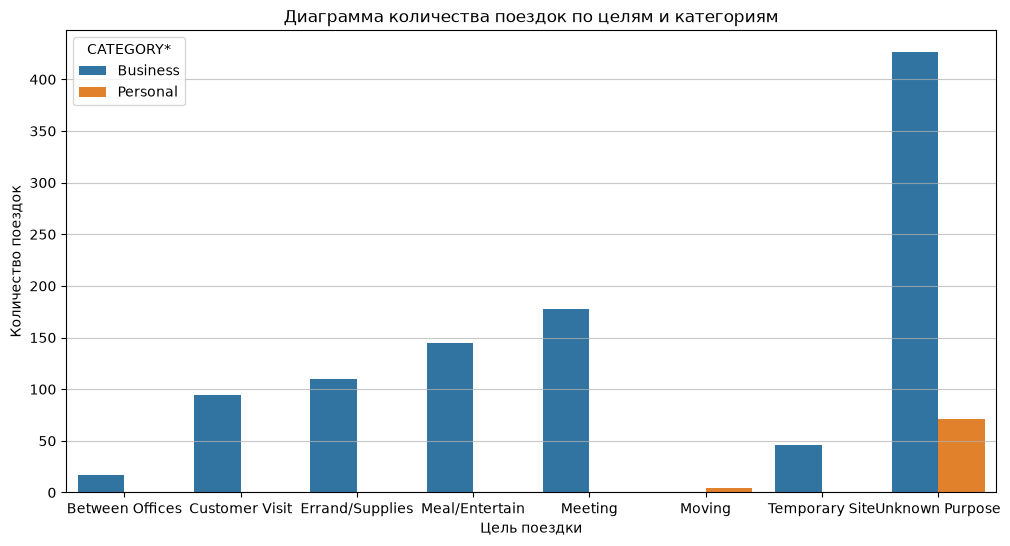

In [18]:
# Подготовка датафрейма
grouped_df = df.groupby(['purpose', 'category']).size().reset_index(name='count')
filtered_df = grouped_df[grouped_df['count']>2]
display(filtered_df)

# Построение столбчатой диаграммы
plt.figure(figsize=(12, 6))

sns.barplot(data=filtered_df, x='purpose', y='count', hue='category')

plt.title('Диаграмма количества поездок по целям и категориям')
plt.xlabel('Цель поездки')
plt.ylabel('Количество поездок')

# Легенда создастся автоматически
plt.legend(title='CATEGORY*')
plt.grid(axis='y', linestyle='-', alpha=0.7) 

По личным делам поездок совершалось сильно меньше, чем по работе, при этом в подавляющем большинстве случаев цель не указывалась. Наиболее популярной целью бизнес-поездки считается деловая встреча (Meeting) - ей соответствует столбец наибольшей высоты (за исключением Unknown Purpose, который в разы превышает все остальные). 

##### Задание 2
Использовать pandas и plot. По сводной таблице
(pivot_table) - отобразить среднее количество пройденных миль по
каждой цели поездки (PURPOSE). Оставить только маркеры в виде ★
зеленого цвета размеров 18.

In [19]:
pivot_df = df.pivot_table(index='purpose', values='miles')
display(pivot_df)

,miles
purpose,
Airport/Travel,6.200000
Between Offices,11.229412
Charity ($),15.100000
Commute,180.200000
Customer Visit,21.896809
Errand/Supplies,4.136364
Meal/Entertain,5.660000
Meeting,15.586517
Moving,4.550000


[Text(0, 0, 'Airport/Travel'),
 Text(1, 0, 'Between Offices'),
 Text(2, 0, 'Charity ($)'),
 Text(3, 0, 'Commute'),
 Text(4, 0, 'Customer Visit'),
 Text(5, 0, 'Errand/Supplies'),
 Text(6, 0, 'Meal/Entertain'),
 Text(7, 0, 'Meeting'),
 Text(8, 0, 'Moving'),
 Text(9, 0, 'Temporary Site'),
 Text(10, 0, 'Unknown Purpose')]

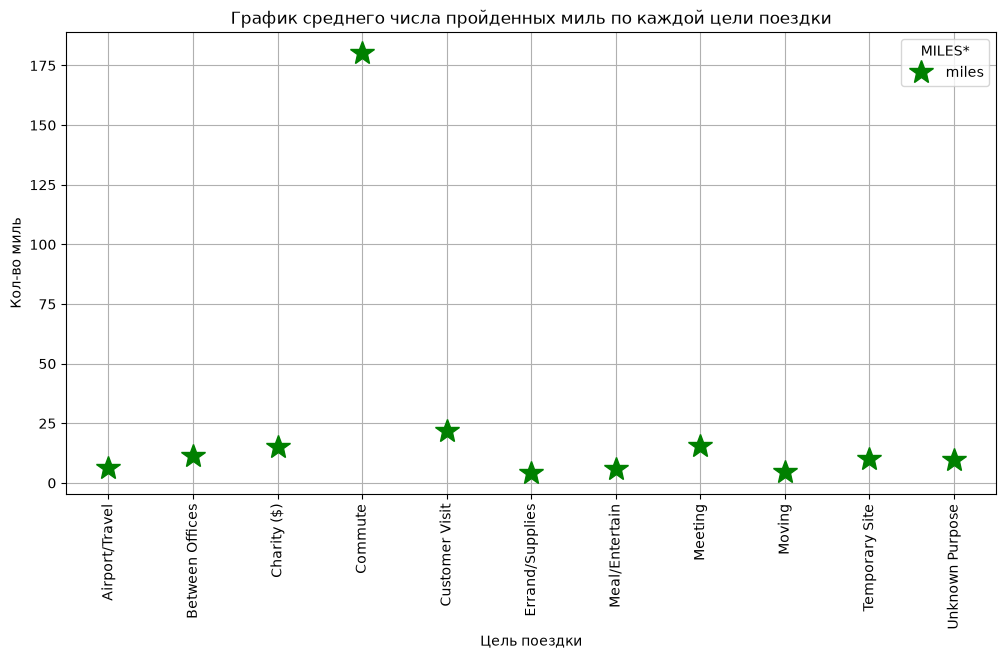

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))
pivot_df.plot(
    kind='line',        
    marker='*',
    markersize=18,
    color='green',
    linestyle='None',
    ax=ax
)
plt.legend(title='MILES*')
plt.title('График среднего числа пройденных миль по каждой цели поездки')
plt.xlabel('Цель поездки')
plt.ylabel('Кол-во миль')
plt.grid(True)
# Принудительная установка засечек для каждой точки по оси X
ax.set_xticks(range(len(pivot_df.index)))

# Установка текстов подписей и поворот их на 90 градусов
ax.set_xticklabels(pivot_df.index, rotation=90) 

Поездки с целью Commute значительно превышают по протяжённости все остальные. Однако, из предыдущей работы известно, что это разовый случай, которого недостаточно для обоснованного вывода об особенности цели. 

##### Задание 3
Использовать matplotlib. Построить круговую диаграмму,
которая отображает процент по каждой цели поездки. Уберите из
диаграммы количество поездок меньше 5.

In [21]:
grouped_df2 = df.groupby('purpose').size().reset_index(name='count')
filtered_df2 = grouped_df2[grouped_df2['count']>5]
display(filtered_df2)

,purpose,count
1,Between Offices,17
4,Customer Visit,94
5,Errand/Supplies,110
6,Meal/Entertain,145
7,Meeting,178
9,Temporary Site,46
10,Unknown Purpose,497


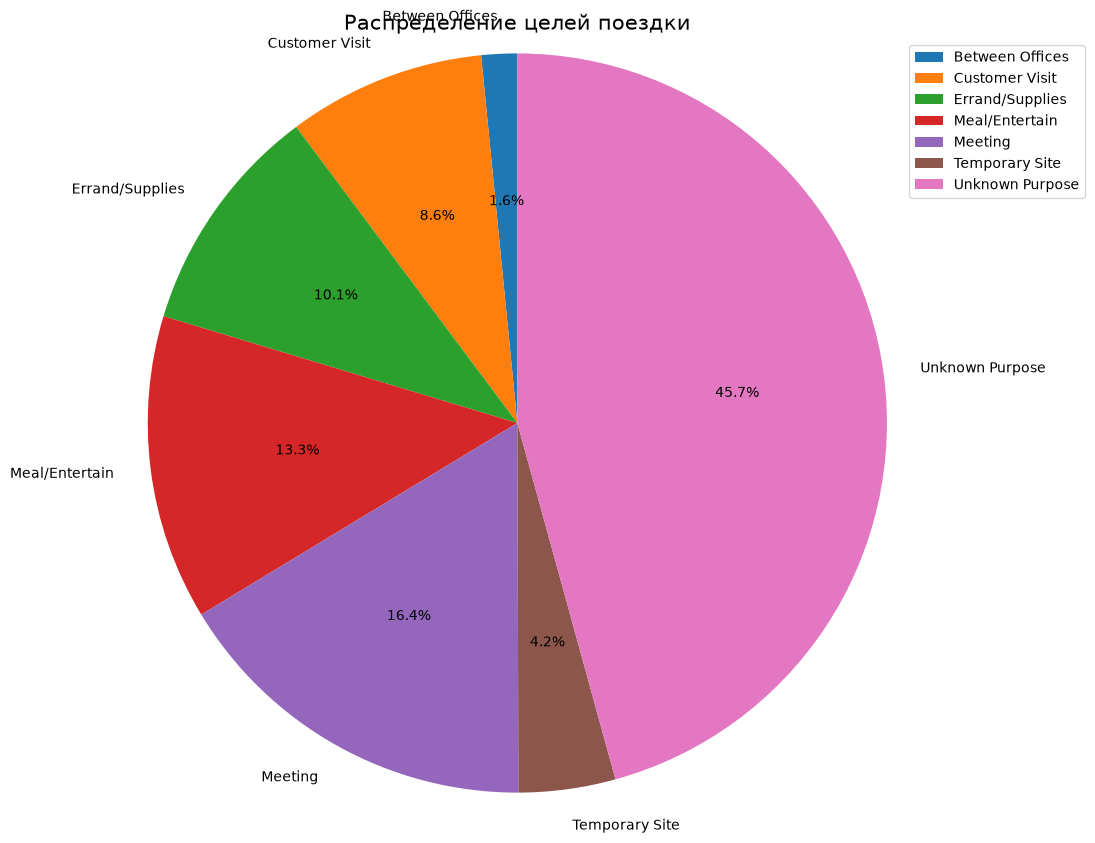

In [22]:
fig, ax = plt.subplots(figsize = (20,10))

ax.pie(filtered_df2['count'], labels=filtered_df2['purpose'], autopct="%.1f%%", radius=1.2,startangle=90)
ax.set_title("Распределение целей поездки", fontsize = 15)
ax.legend(fontsize = 10,  bbox_to_anchor=(1, 1))

Почти половину всей круговой диаграммы занимает Unknown Purpose.

#### 2.5 Специальные типы графиков
##### 2.5.1 Hexagonal binning plot

**Hexagonal binning plot** – график делится на ячейки, которые заливаются цветом – чем больше точек попало в область,
тем цвет гуще. Таким образом, этот график отображает частотность двух величин.

<Axes: title={'center': 'Визуализаця частотности пар признаков miles и speed'}, xlabel='miles', ylabel='speed'>

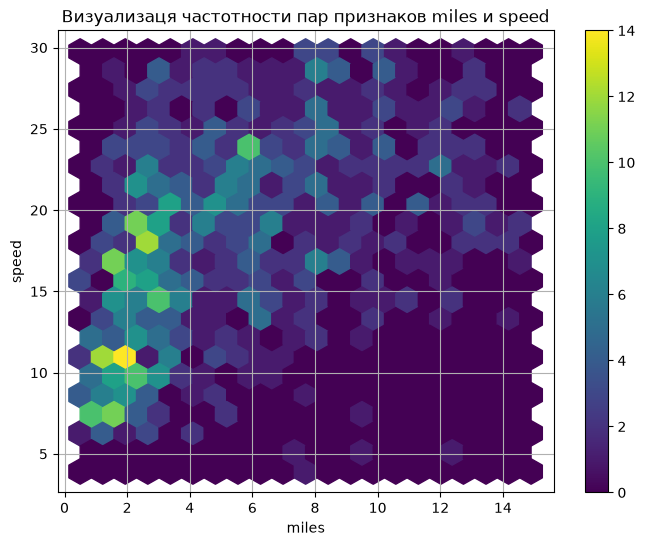

In [77]:
# df.describe()
filtered_df2 = df[(df['miles'] < 15) & (df['speed'] < 30)]
filtered_df2.plot(x='miles', y='speed', kind='hexbin', gridsize=20, figsize=(8, 6), sharex=False, grid=True, title ='Визуализаця частотности пар признаков miles и speed', cmap='viridis')

Использование шестиугольных ячеек позволило избавиться от проблемы перекрытия точек, которая возникла при построении обычной точечной диаграммы (см. пункт 2.1 отчёт) из-за большого объема данных. На графике видно, что подавляющее большинство поездок сконцентрировано в области до 10 миль и скорости до 25 миль/ч (самые темные шестиугольники). Также график наглядно демонстрирует наличие аномально высоких скоростей (выбросов), уходящих далеко вверх, что подтверждает выводы, сделанные при анализе матрицы корреляций.

##### 2.5.2 boxplot
**Диаграмма размаха** («ящик с усами») – графический инструмент, который представляет распределение данных по основным статистическим показателям. В основе графика лежит
прямоугольник («ящик»), из боковых сторон которого исходят отрезки («усы»).  
Диаграмма размаха позволяет быстро оценить основные характеристики распределения и выявить наличие выбросов или аномалий. «Ящик» на диаграмме ограничен Q1 и Q3, а внутри ящика показывается медиана. «Усы» на диаграмме равны 1,5 межквартильного размаха, в них попадают нормальные значения, а за их пределами показаны **выбросы**, которые представляют собой точки.  


Text(0.5, 1.0, 'Boxplot для miles (с ограничением оси X)')

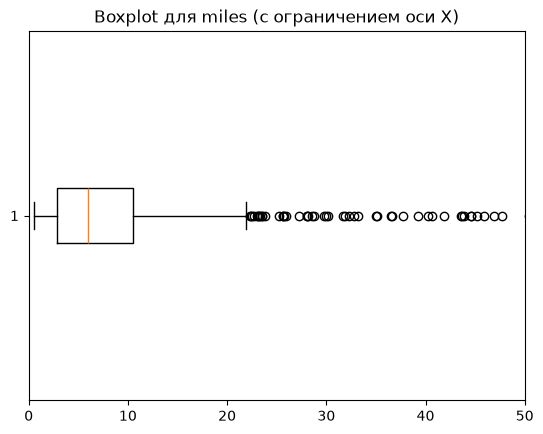

In [24]:
plt.boxplot(df['miles'], orientation = 'horizontal')
plt.xlim(0, 50)
plt.title('Boxplot для miles (с ограничением оси X)')

Коробка (межквартильный размах, где лежат 50% всех данных) находится в диапазоне примерно от 3 до 10 миль. но есть выбросы > 300 миль. Из-за этого на графике растянется ось X от 0 до 310, что мешает восприятию. Метод xlim позволяет ограничить оси или скрыть выброс, что визуально увеличит коробку и улучшит график для восприятия.  
Видно, что медиана находится около 6 миль, а 50% всех поездок укладываются в диапазон от 3 до 10.5 миль. «Усы» простираются до 20 миль, а всё, что уходит дальше, считается выбросами.

##### 2.5.3 boxplot с категориями
Задание: Добавьте категорию по любому числовому столбцу (например, уровень зарплаты - высокий, низкий, средний). Сделайте boxplot по этому числовому столбцу по каждой новой категории (на boxplot будет box-ы для средней, низкой и высокой зарплаты).  
Создадим столбец “Категория длительности поездки”. При этом выделяются 3 категории длительности поездки: короткая, длинная, средняя. 

In [25]:
df['drive_time'] = (df['end_date']-df['start_date']).dt.total_seconds()//60
df['drive_time'].describe()

count    1095.000000
mean       23.385388
std        27.760654
min         1.000000
25%        10.000000
50%        16.000000
75%        27.500000
max       336.000000
Name: drive_time, dtype: float64

Разделим значения длительности поездки на категории следующим образом:
- Короткие поездки:  drive_time <= 10 (меньше Q1);
- Средние поездки:  10< drive_time < 27.5 (между Q1 и Q3);
- Длинные поездки:  drive_time >= 27.5 (больше Q3);

Использование квартилей позволяет создать устойчивые к выбросам категории, отражающие реальную структуру данных: большинство поездок попадут в средний диапазон.

In [38]:
duration_cat = ['short', 'average', 'long']

df['duration_category'] = pd.cut(df['drive_time'], bins=[0, 10, 27.5, 350], labels=duration_cat) # длина списка меток на 1 меньше кол-ва интервалов
df['duration_category'].value_counts()

duration_category
average    515
short      306
long       274
Name: count, dtype: int64

(0.0, 100.0)

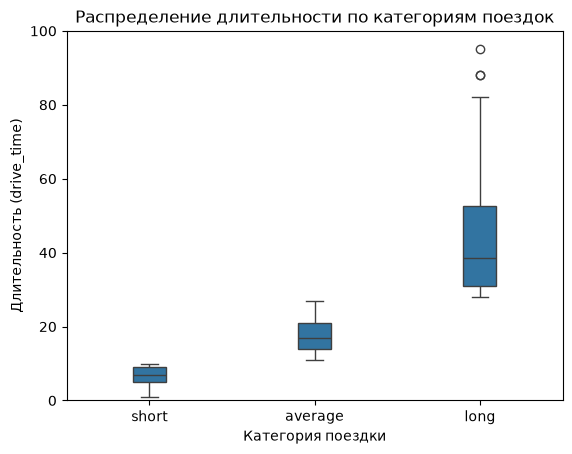

In [71]:
sns.boxplot(x = df['duration_category'], y = df['drive_time'], width = 0.2) # диаграмма по каждой категории столбца fueltype (y - числовой, x - категориальный)
plt.title('Распределение длительности по категориям поездок')
plt.xlabel('Категория поездки')
plt.ylabel('Длительность (drive_time)')

plt.ylim(0, 100)

Боксы расположены друг под другом, что подтверждает корректность категоризации.  Ящики распределены строго по возрастанию, а их границы не пересекаются, что соответствует заданным интервалам (до 10, от 10 до 27.5, свыше 27.5 минут).  
«Усы» показывают разброс данных внутри каждой категории (от минимального до максимального значения, исключая выбросы).
- short (короткий ус): Поездки от 0 до 10 минут. Разброс очень маленький, данные плотно сгруппированы.
- average (средний ус): Поездки от 10 до 27.5 минут. Разброс больше, но всё еще ограничен жесткими рамками.
- long (длинный ус): Разброс огромный. Верхний ус уходит далеко вверх (до 80 минут), потому что в эту категорию попали все поездки от 27.5 минут и до бесконечности. Чем шире диапазон реальных значений в категории, тем длиннее будут усы. При этом на графике стоит ограничение plt.ylim(0, 100), поэтому видны только два выброса около 90 минут. Если убрать это ограничение, отобразятся еще несколько кружочков далеко наверху —  аномально долгие поездки на 150-300 минут.

Для дополнительного анализа построим ещё две диаграммы размаха с разделением **на те же категории**:


(0.0, 50.0)

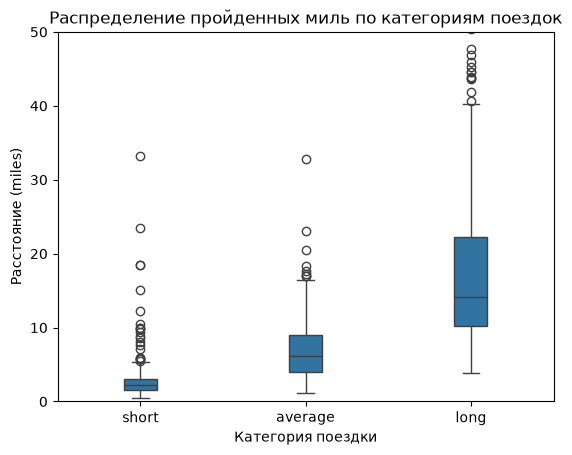

In [69]:
sns.boxplot(x = df['duration_category'], y = df['miles'], width = 0.2) # диаграмма по каждой категории столбца fueltype (y - числовой, x - категориальный)
plt.title('Распределение пройденных миль по категориям поездок')
plt.xlabel('Категория поездки')
plt.ylabel('Расстояние (miles)')

plt.ylim(0, 50)

При построении диаграммы размаха для признака miles по категориям времени (duration_category) наблюдается тенденция: медианное расстояние растет от коротких поездок к длинным (около 2 миль для short, 6 миль для average и 15 миль для long). Межквартильный размах (размер «ящиков») и длина «усов» также увеличиваются, что говорит о возрастающем разбросе значений. В отличие от предыдущего графика (где по оси y было само время), здесь «усы» категорий пересекаются, а выбросы присутствуют во всех трех группах. Это связано с тем, что нет жесткой зависимости между временем и расстоянием. Так например, короткая по времени поездка (short) может иметь большую дальность (быстрая езда по трассе), и наоборот — долгая поездка (long) может быть короткой по расстоянию (стояние в пробке). Выбросы в категории short (поездки на 20 миль и более) как раз иллюстрируют такие быстрые дальние маршруты.

(0.0, 50.0)

<Figure size 800x500 with 0 Axes>

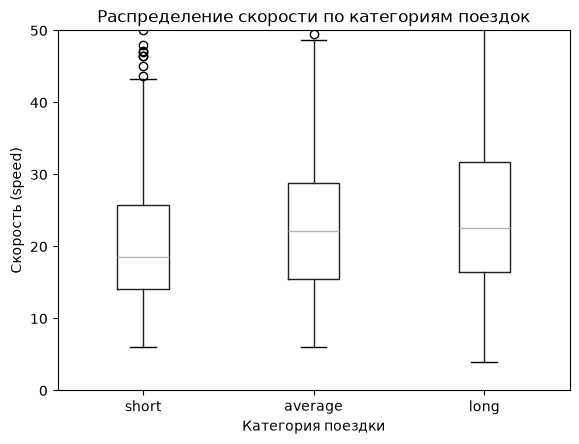

In [74]:
plt.figure(figsize=(8, 5))

# Встроенный метод Pandas
df.boxplot(column='speed', by='duration_category', grid=False)

plt.suptitle('') # Убираем автоматический заголовок
plt.title('Распределение скорости по категориям поездок')
plt.xlabel('Категория поездки')
plt.ylabel('Скорость (speed)')

# ограничение оси Y, чтобы убрать экстремальные выбросы
plt.ylim(0, 50) 

При исследовании зависимости скорости (speed) от категории длительности поездки (duration_category) было выявлено, что медианные значения скорости для всех трех категорий находятся примерно на одном уровне (около 18–23 км/ч). Можно сказать, что средняя скорость движения слабо зависит от того, сколько времени занимает поездка — ограничения дорожного трафика действуют одинаково. Однако наблюдается небольшое увеличение разброса данных (размера ящиков и длины усов) от категории short к категории long. В коротких поездках скорость ограничена узким диапазоном, в длинных разброс становится большим. Это объясняется тем, что долгие поездки неоднородны по условиям: они могут проходить как в плотном городском трафике (низкая скорость), так и по загородным трассам (высокая скорость). Наличие выбросов во всех категориях также указывает на присутствие в данных аномальных значений.

### Вывод

В ходе работы был проведен исследовательский анализ данных (EDA) набора drivers.csv, содержащего информацию о поездках такси (даты, категории, локации, расстояние, время, цель и стоимость). Перед началом визуализации была выполнена предобработка: устранены пропуски (501 пропуск в целях поездки заменен на Unknown Purpose, удалены 4 строки с нулевым временем), даты приведены к формату datetime, а также создан производный признак drive_time (время в минутах) и его категоризация (duration_category).  
Анализ распределений (гистограммы и матрица рассеяния pairplot) показал, что все числовые признаки имеют ярко выраженную правостороннюю асимметрию. Большинство поездок являются короткими (до 10 миль) и недорогими, однако присутствует длинный «хвост» из редких экстремальных значений (выбросов).  
Корреляционный анализ выявил следующие закономерности:
- обнаружена почти абсолютная линейная связь между временем и ценой (r ≈ 0.99), что свидетельствует о расчете стоимости такси исключительно по времени (тарифу по минутам).
- расчет ковариации подтвердил положительную направленность связей, но из-за разницы масштабов (рубли, минуты, мили) для оценки силы использовалась корреляция. Сравнение Пирсона и Спирмена показало, что наличие экстремальных выбросов в скорости (до 800 миль/ч) искажает линейную корреляцию, однако ранговая корреляция Спирмена выявила умеренную монотонную связь между расстоянием и скоростью (0.63).
Построение Hexagonal binning plot и диаграмм размаха (boxplot) позволило детализировать структуру данных. Hexbin после фильтрации выбросов наглядно показал концентрацию поездок в области малых расстояний и скоростей. Анализ boxplot по категориям длительности поездки доказал, что чем дольше поездка, тем больше среднее расстояние (медиана растет с 2 до 15 миль), однако медианная скорость остается неизменной (~20–23 км/ч), а разброс значений увеличивается.
Данные содержат шумы и аномалии (ошибочные скорости, поездки с нулевым временем), которые требуют очистки, однако даже в очищенном виде они демонстрируют логичные закономерности: преобладание коротких деловых поездок, зависимость стоимости от времени в пути и влияние дорожной обстановки на скорость движения.